# 11. RG3 교차확인 + RG3 정상 vs 불량 구분

**PART 1 — CN7 R1 가스 패턴이 RG3에서도 나오나**
- 변수를 **Run 안에서 표준화(run_z)** 후 합침 → Run끼리의 수준 차이 제거, '같은 Run 안에서 불량이 높나/낮나'만 봄
- 비교군: 같은 Run 정상 전체 / 불량 앞뒤 ±10샷 정상(시간 추세 통제)
- Run별 δ와 **같은 방향 Run 수** → 한 Run 때문인지, 여러 Run에서 반복되는지
- 시간 군집 검정 (CN7 R1은 49~58번째에 가스 9개 몰림) / Run 수준 상태 vs 불량률

**PART 2 — RG3 정상 vs 불량 구분 가능성**
- 단변량 표·그래프 + 다변량 LORO logit + 라벨 섞기 귀무분포 → '우연 이상으로 구분되나'
- 캐비티(LH/RH) 분포

※ run_z는 Run 전체로 계산(미래 샷 포함) → 현장 예측용이 아니라 **차이·구분 가능성 확인용**

In [1]:
%load_ext autoreload
%autoreload 2
import os
import pandas as pd
from run_compare import (load_product, variable_list, add_run_z, both_pooled, hypothesis_check, cluster_test,
                         run_level_table, separability_loro, cavity_table, GAS_HYP,
                         plot_hypothesis, plot_per_run_heat, plot_run_timelines, plot_run_level,
                         plot_top2, plot_separability)
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 40)
OUT = './outputs/rg3_compare'
os.makedirs(OUT, exist_ok=True)
WINDOW = 10

D, RUNS, Z, COLS = {}, {}, {}, {}
for p in ['cn7', 'rg3']:
    D[p], RUNS[p] = load_product(p)
    COLS[p] = variable_list(D[p])
    Z[p] = add_run_z(D[p], COLS[p])
display(RUNS['rg3'])

[cn7] 샷 1974, 불량 15
[rg3] 샷 627, 불량 32


,샷,불량,가스,미성형계열,LH불량,RH불량,불량률
run_id,,,,,,,
rg3_R1,41,0,0,0,0.0,0.0,0.000
rg3_R2,103,5,4,1,0.0,5.0,0.049
rg3_R3,197,10,6,4,0.0,10.0,0.051
rg3_R4,74,4,3,1,0.0,4.0,0.054
rg3_R5,176,6,4,2,0.0,6.0,0.034
rg3_R6,36,7,5,2,5.0,2.0,0.194


## PART 1-1. 가스 가설 재현 — CN7 R1 vs RG3 (시간 맞춤 δ)

,변수,이름,cliffs_delta_CN7,cliffs_delta_시간맞춤_CN7,cliffs_delta_RG3,cliffs_delta_시간맞춤_RG3,같은방향_Run,같은방향_Run_시간맞춤,q_FDR,방향 재현,RG3도 중간 이상
0,Hopper_Temperature_raw,호퍼온도,0.377,0.600,-0.115,-0.069,2/5,2/5,0.914,False,False
1,Mold_Temperature_3_raw,금형온도3,0.518,0.077,-0.050,0.107,2/5,3/5,0.914,True,False
2,Plasticizing_Time_raw,계량시간,0.162,0.409,0.114,0.160,4/5,4/5,0.914,True,False
3,dev_Hopper_Temperature,Δ기준선·호퍼온도,0.564,0.620,-0.050,-0.021,2/5,2/5,0.914,False,False
4,dev_Mold_Temperature_3,Δ기준선·금형온도3,-0.350,-0.534,0.161,0.200,4/5,3/5,0.914,False,False
5,hopper_rise,호퍼·rise,0.376,0.600,-0.126,-0.076,2/5,2/5,0.914,False,False
6,hopper_slope20,호퍼·slope20,0.524,0.755,-0.108,-0.082,3/5,3/5,0.914,False,False
7,mold_slope20,금형·slope20,-0.008,-0.264,-0.032,-0.062,3/5,3/5,0.914,True,False


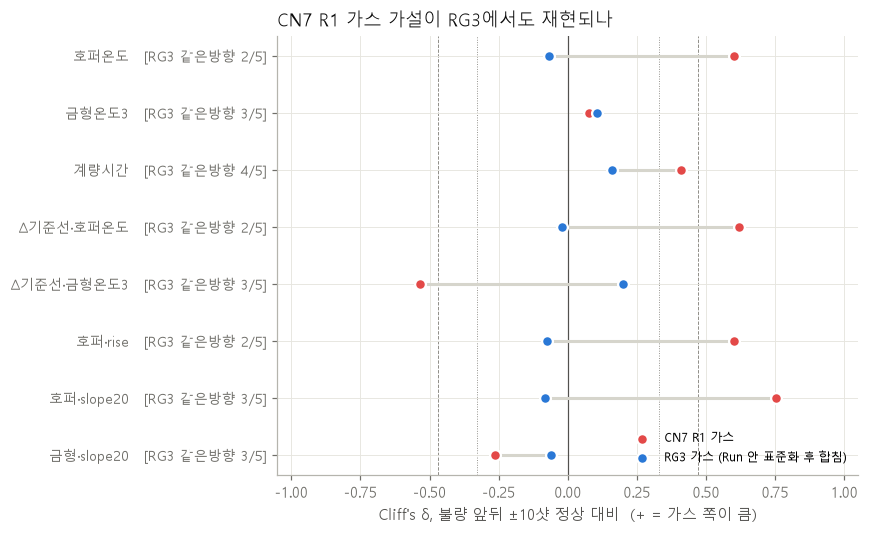

In [2]:
T = {p: both_pooled(D[p], Z[p], COLS[p], '가스', WINDOW) for p in ['cn7', 'rg3']}
T['rg3'].to_csv(f'{OUT}/rg3_gas_table.csv', index=False, encoding='utf-8-sig')
H = hypothesis_check(T['cn7'], T['rg3'])
H.to_csv(f'{OUT}/gas_hypothesis.csv', index=False, encoding='utf-8-sig')
display(H.round(3))
plot_hypothesis(H, save=f'{OUT}/gas_hypothesis.png')

## PART 1-2. RG3 가스 — 전체 변수 표 + Run별 일관성

,이름,n불량,med_z_불량,cliffs_delta,q_FDR,같은방향_Run,cliffs_delta_시간맞춤,q_FDR_시간맞춤,같은방향_Run_시간맞춤,일관
0,Δ기준선·사이클,22,0.000,0.205,0.914,4/5,0.230,0.85,4/5,False
1,사이클,22,0.000,0.182,0.914,4/5,0.214,0.85,4/5,False
2,Δ기준선·금형온도3,22,0.500,0.161,0.914,4/5,0.200,0.85,3/5,False
3,배럴5,22,0.250,0.170,0.914,4/5,0.182,0.85,4/5,False
4,형체시간,22,0.000,0.155,0.914,2/2,0.163,0.85,2/2,False
5,Δ기준선·흐름저항,22,-0.328,-0.150,0.914,4/5,-0.163,0.85,4/5,False
6,계량시간,22,0.000,0.114,0.914,4/5,0.160,0.85,4/5,False
7,배럴4,22,0.038,0.157,0.914,4/5,0.153,0.85,4/5,False
8,절환압,22,0.125,0.084,0.914,3/5,0.136,0.85,4/5,False
9,금형·rise,22,0.000,-0.025,0.939,2/5,0.129,0.85,3/5,False


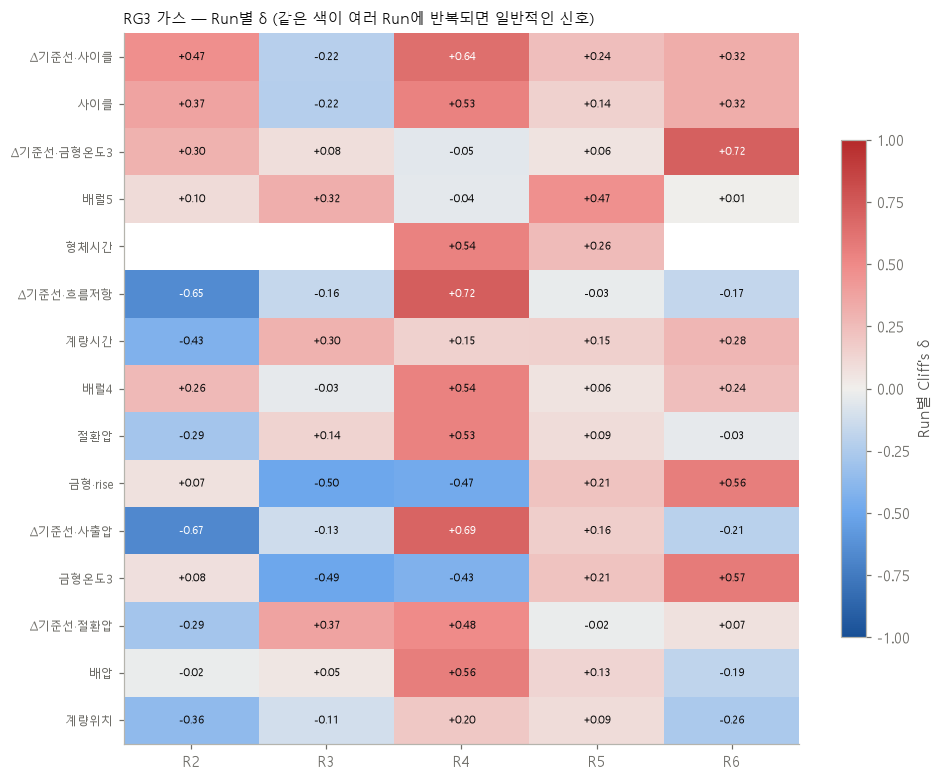

In [3]:
cols_show = ['이름', 'n불량', 'med_z_불량', 'cliffs_delta', 'q_FDR', '같은방향_Run',
             'cliffs_delta_시간맞춤', 'q_FDR_시간맞춤', '같은방향_Run_시간맞춤', '일관']
display(T['rg3'][cols_show].head(20).round(3))
plot_per_run_heat(T['rg3'], title='RG3 가스 — Run별 δ (같은 색이 여러 Run에 반복되면 일반적인 신호)',
                  save=f'{OUT}/rg3_gas_per_run.png')

## PART 1-3. 시간 군집 — 가스가 Run 안에서 몰려 나오나

In [4]:
for p in ['cn7', 'rg3']:
    res, tab, null = cluster_test(D[p], '가스')
    print(f'[{p}]', {k: round(v, 3) for k, v in res.items()})
    display(tab)

[cn7] {'관측 평균 최근접 거리': np.float64(3.091), '무작위 평균': np.float64(9.485), 'p(몰림)': np.float64(0.002)}


,Run,샷,가스 수,가스 순번
0,cn7_R1,188,11,"[25, 41, 49, 51, 52, 53, 54, 55, 56, 57, 58]"


[rg3] {'관측 평균 최근접 거리': np.float64(17.364), '무작위 평균': np.float64(16.019), 'p(몰림)': np.float64(0.665)}


,Run,샷,가스 수,가스 순번
0,rg3_R2,103,4,"[28, 40, 62, 82]"
1,rg3_R3,197,6,"[7, 12, 18, 30, 62, 167]"
2,rg3_R4,74,3,"[3, 23, 41]"
3,rg3_R5,176,4,"[33, 72, 146, 152]"
4,rg3_R6,36,5,"[14, 15, 18, 25, 26]"


## PART 1-4. Run 타임라인 (가설 변수 + 사출 계열)

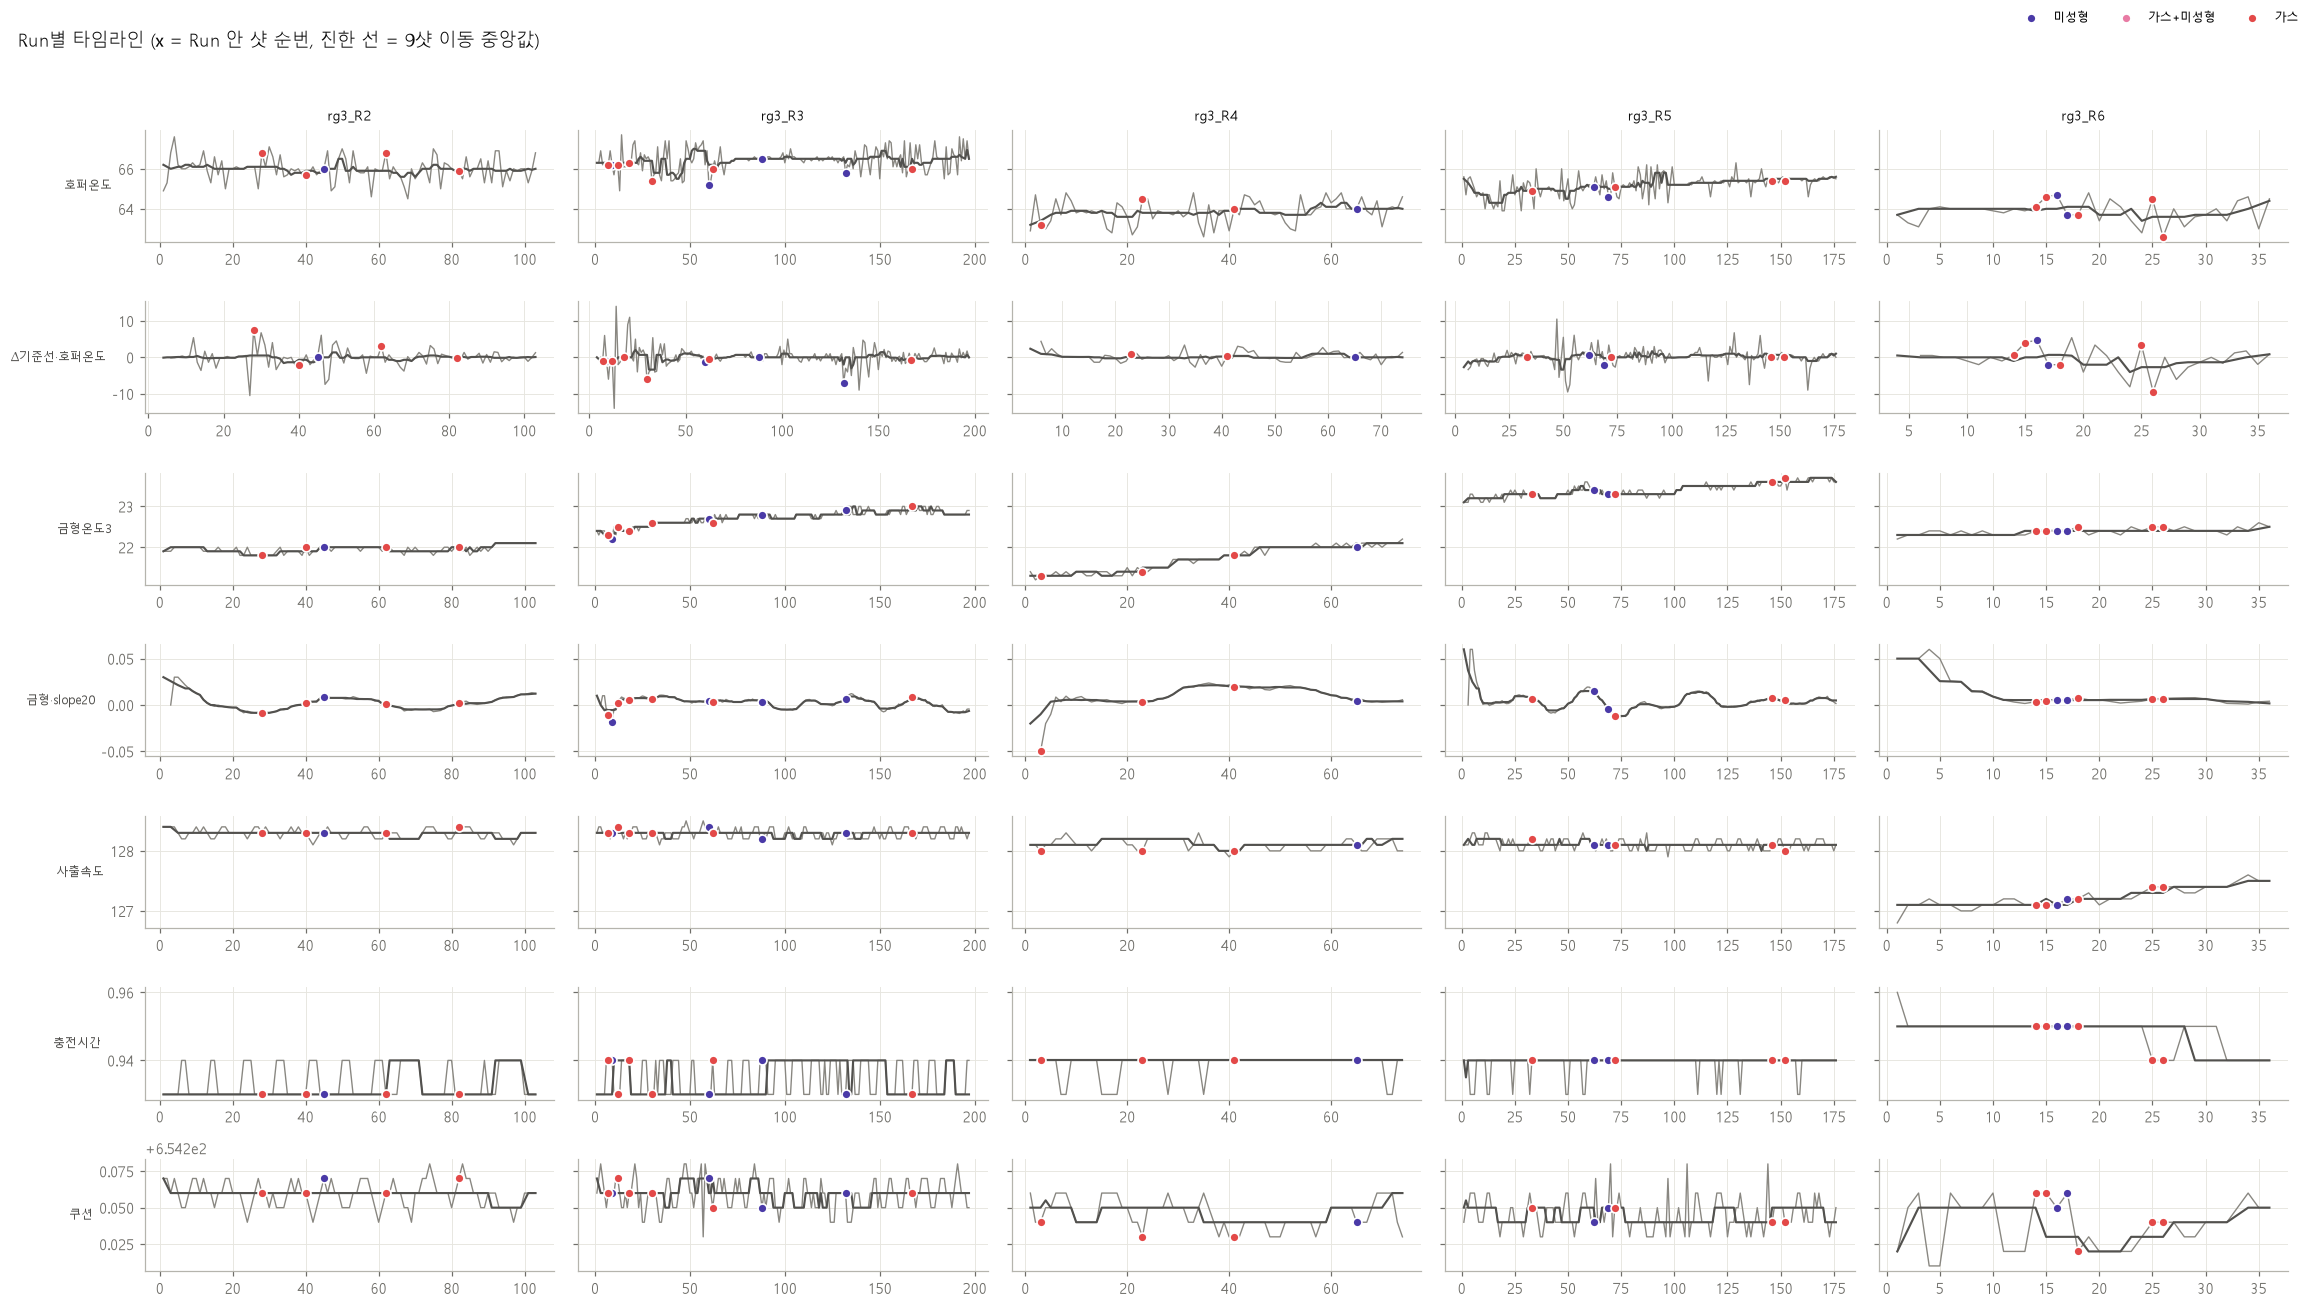

In [5]:
TL = ['Hopper_Temperature_raw', 'dev_Hopper_Temperature', 'Mold_Temperature_3_raw', 'mold_slope20',
      'Max_Injection_Speed_raw', 'Filling_Time_raw', 'Cushion_Position_raw']
plot_run_timelines(D['rg3'], [c for c in TL if c in D['rg3']], save=f'{OUT}/rg3_timelines.png')

## PART 1-5. Run 수준 — Run 상태 vs 불량률 (Run 6개, 경향만)

,샷,불량률,가스율,금형온도3,호퍼온도,흐름저항,배럴4,계량위치
run_id,,,,,,,,
rg3_R1,41,0.000,0.000,21.4,65.8,1.109,275.40,53.59
rg3_R2,103,0.049,0.039,22.0,66.0,1.111,275.30,53.59
rg3_R3,197,0.051,0.030,22.8,66.5,1.111,275.50,53.57
rg3_R4,74,0.054,0.041,21.7,63.9,1.114,275.20,53.59
rg3_R5,176,0.034,0.023,23.4,65.3,1.114,275.45,53.59
rg3_R6,36,0.194,0.139,22.4,64.0,1.127,275.35,53.61


,상태,대상,Spearman ρ,p,Run 수
0,금형온도3,불량률,0.143,0.787,6
1,금형온도3,가스율,0.029,0.957,6
2,호퍼온도,불량률,-0.429,0.397,6
3,호퍼온도,가스율,-0.486,0.329,6
4,흐름저항,불량률,0.736,0.096,6
5,흐름저항,가스율,0.736,0.096,6
6,배럴4,불량률,-0.371,0.468,6
7,배럴4,가스율,-0.600,0.208,6
8,계량위치,불량률,0.338,0.512,6
9,계량위치,가스율,0.507,0.305,6


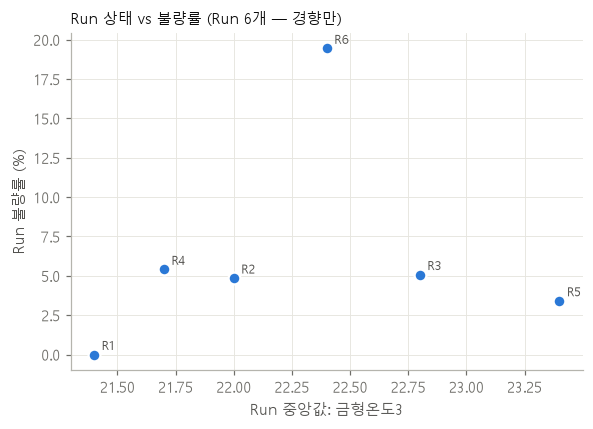

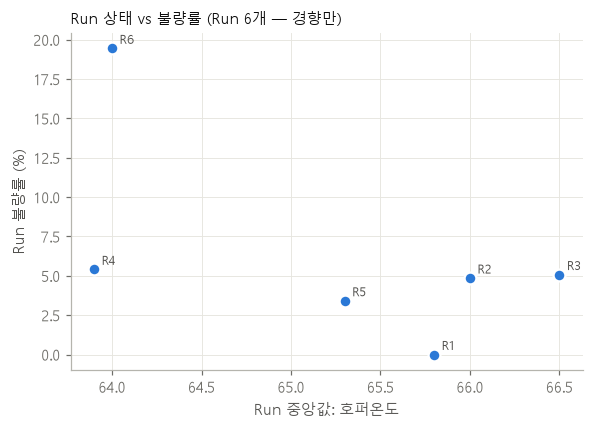

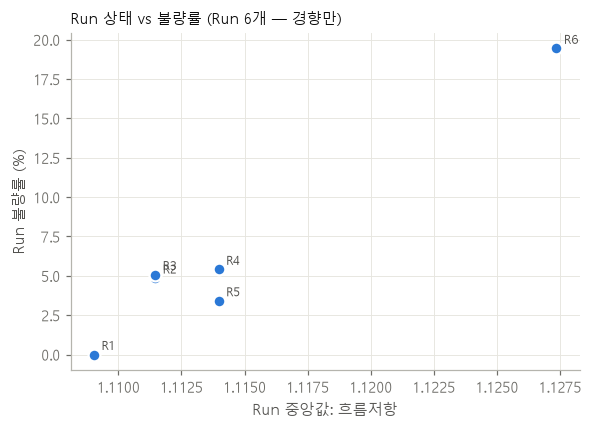

In [6]:
RL, RC = run_level_table(D['rg3'])
display(RL.round(3)); display(RC.round(3))
for x in ['금형온도3', '호퍼온도', '흐름저항']:
    if x in RL:
        plot_run_level(RL, x, save=f'{OUT}/run_level_{x}.png')

## PART 2-1. RG3 정상 vs 불량 — 단변량 (전체불량 / 미성형계열)

===== RG3 전체불량 =====


,이름,n불량,med_z_불량,cliffs_delta,q_FDR,같은방향_Run,cliffs_delta_시간맞춤,q_FDR_시간맞춤,같은방향_Run_시간맞춤,일관
0,계량시간,32,0.235,0.223,0.647,3/5,0.212,0.720,3/5,False
1,배럴5,32,0.250,0.164,0.673,4/5,0.176,0.720,4/5,False
2,Δ기준선·금형온도3,32,0.500,0.136,0.793,3/5,0.162,0.720,3/5,False
3,Δ기준선·계량시간,32,0.291,0.187,0.673,3/5,0.157,0.720,3/5,False
4,사이클,32,0.000,0.141,0.673,4/5,0.154,0.720,4/5,False
5,호퍼·rise,32,-0.417,-0.176,0.673,2/5,-0.149,0.720,2/5,False
6,절환압,32,0.250,0.114,0.827,4/5,0.147,0.720,4/5,False
7,Δ기준선·사이클,32,0.000,0.126,0.793,4/5,0.142,0.720,4/5,False
8,호퍼온도,32,-0.417,-0.164,0.673,2/5,-0.141,0.720,2/5,False
9,Δ기준선·절환압,32,0.250,0.134,0.793,3/5,0.138,0.720,4/5,False


===== RG3 미성형계열 =====


,이름,n불량,med_z_불량,cliffs_delta,q_FDR,같은방향_Run,cliffs_delta_시간맞춤,q_FDR_시간맞춤,같은방향_Run_시간맞춤,일관
0,Δ기준선·계량시간,10,0.761,0.458,0.169,3/3,0.395,0.735,3/3,True
1,계량시간,10,0.610,0.463,0.169,3/3,0.361,0.735,3/3,True
2,호퍼·rise,10,-0.443,-0.285,0.801,2/3,-0.278,0.833,2/3,False
3,호퍼온도,10,-0.439,-0.270,0.801,2/3,-0.268,0.833,2/3,False
4,호퍼·slope20,10,0.337,0.270,0.801,3/3,0.261,0.833,3/3,False
5,계량위치,10,0.000,0.287,0.801,2/3,0.251,0.833,2/3,False
6,Δ기준선·호퍼온도,10,-0.250,-0.255,0.805,2/3,-0.244,0.833,2/3,False
7,Δ기준선·절환압,10,0.352,0.238,0.853,2/3,0.218,0.833,3/3,False
8,절환압,10,0.500,0.180,0.961,3/3,0.217,0.833,3/3,False
9,Δ기준선·사출압,10,0.250,0.155,0.961,2/3,0.214,0.833,2/3,False


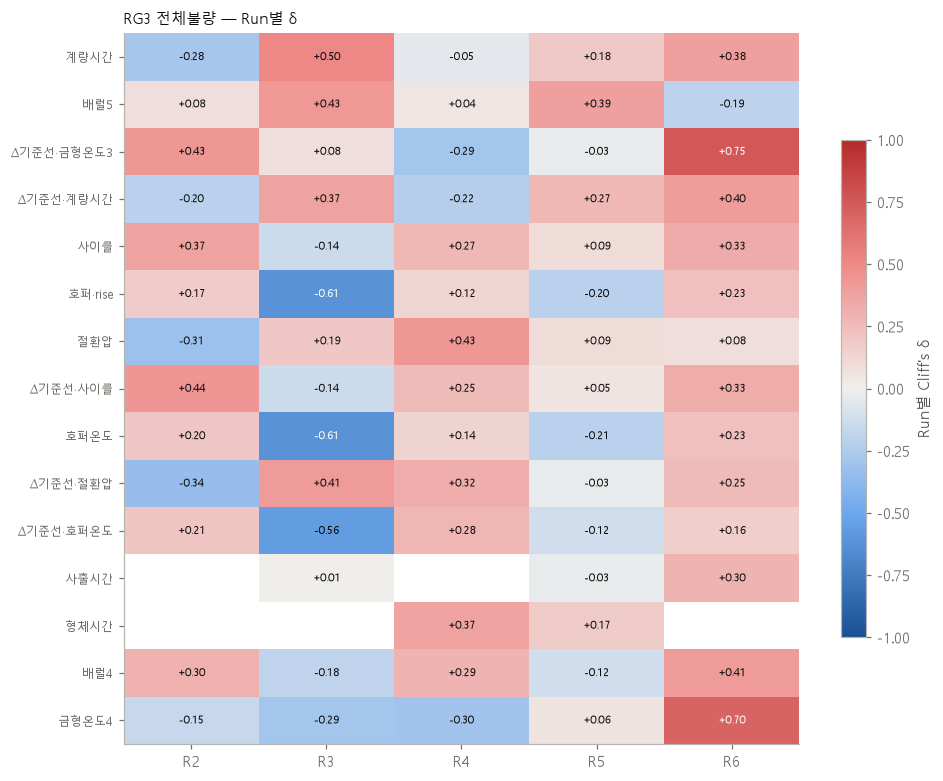

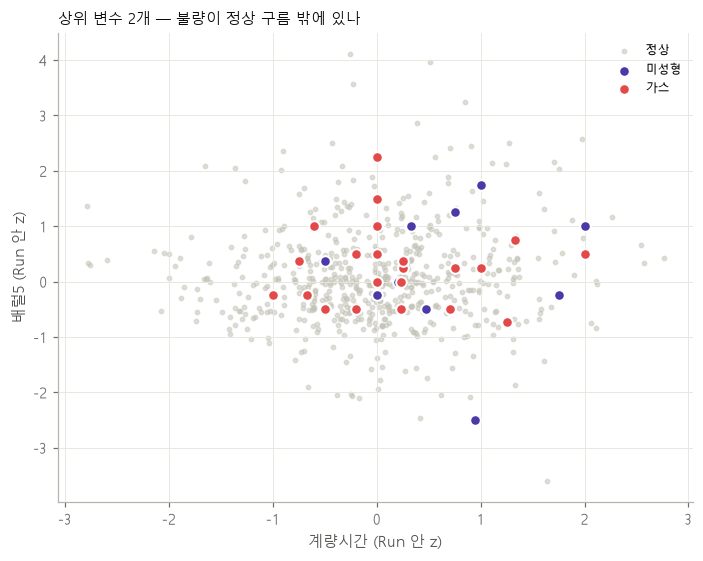

In [7]:
T2 = {g: both_pooled(D['rg3'], Z['rg3'], COLS['rg3'], g, WINDOW) for g in ['전체불량', '미성형계열']}
for g, t in T2.items():
    t.to_csv(f'{OUT}/rg3_{g}_table.csv', index=False, encoding='utf-8-sig')
    print(f'===== RG3 {g} ====='); display(t[cols_show].head(15).round(3))
plot_per_run_heat(T2['전체불량'], title='RG3 전체불량 — Run별 δ', save=f'{OUT}/rg3_all_per_run.png')
plot_top2(D['rg3'], Z['rg3'], T2['전체불량'], save=f'{OUT}/rg3_top2.png')

## PART 2-2. 다변량 구분 가능성 — LORO logit + 라벨 섞기 (200회)

{'LORO AUC': 0.466, 'Run별 AUC 평균': np.float64(0.459), 'Run별 AUC': {'rg3_R2': 0.23877551020408166, 'rg3_R3': 0.47700534759358293, 'rg3_R4': 0.5285714285714286, 'rg3_R5': 0.5931372549019608, 'rg3_R6': 0.458128078817734}, '귀무 AUC 평균': np.float64(0.493), '귀무 95%': np.float64(0.61), 'p(우연)': np.float64(0.652)}


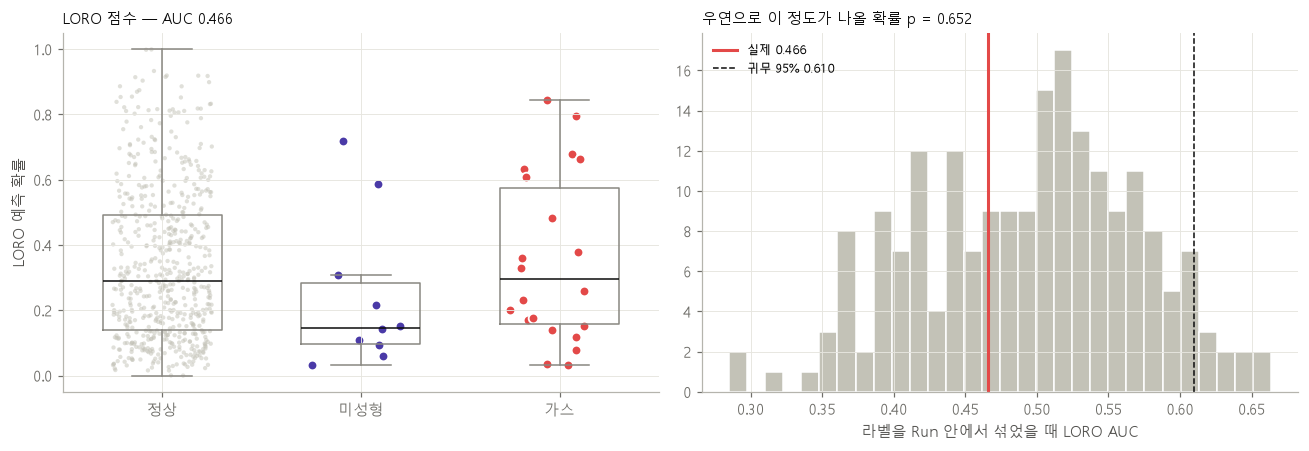

In [8]:
SUMM, OOF, NULL = separability_loro(D['rg3'], Z['rg3'], COLS['rg3'], n_perm=200)
print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in SUMM.items()})
OOF.to_csv(f'{OUT}/rg3_sep_oof.csv', index=False, encoding='utf-8-sig')
plot_separability(SUMM, OOF, NULL, save=f'{OUT}/rg3_separability.png')

## PART 2-3. 캐비티 — 불량이 어느 쪽에서 났나

In [9]:
display(cavity_table(D['rg3']))

Reason  가스     미성형      합계
캐비티    LH만 RH만 LH만 RH만    
run_id                    
rg3_R2   0   4   0   1   5
rg3_R3   0   6   0   4  10
rg3_R4   0   3   0   1   4
rg3_R5   0   4   0   2   6
rg3_R6   3   2   2   0   7
합계       3  19   2   8  32

## 해석 체크리스트
- **가설 재현**: 호퍼↑·금형온도 편차↓가 RG3에서도 같은 방향 + |δ|≥0.33 + 같은방향 Run 다수 → 가스 공통 메커니즘 근거
  (방향만 같고 δ가 작으면 '약한 재현', 반대면 '재현 안 됨' → CN7 R1 결과는 그 Run 특유일 가능성)
- **시간 군집**: p(몰림) < 0.05면 가스가 구간 단위로 발생 → 구간·상태 모니터링 근거
- **구분 가능성**: LORO AUC가 귀무 95% 선을 못 넘으면 → RG3는 공정 변수로 정상/불량 구분 불가 (보고서 실패 조건)
- **캐비티**: RH만 불량인데 공정값은 LH/RH 공통 → 캐비티 쪽 원인(금형 RH측 벤트·게이트 등)은 이 데이터로 설명 불가